Import libraries

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import to_hex
from pathlib import Path
import seaborn as sns
from datetime import datetime
import matplotlib.gridspec as gridspec
from behavior.vr import analyse as an
from common.io import get_behavior_vr_root, get_panels_root     # replacement for utils.get_data_paths()
from common.plotting import use_style
from IPython.display import HTML, display
import matplotlib.patches as mpatches
from matplotlib.legend_handler import HandlerTuple
import re
from matplotlib.lines import Line2D

plt.rcParams['figure.dpi'] = 180
use_style()

display(HTML("<style>.output_scroll {height: 480px; overflow-y: scroll;}</style>"))

##### Define file paths

In [2]:
DATA_ROOT = get_behavior_vr_root()   # auto-detects Mac + hd
print("DATA_ROOT:", DATA_ROOT)
FIGURE = "fig2"
plot_path = get_panels_root("paper") / FIGURE / "panels"

DATA_ROOT: /Volumes/LAB-MATI/Lausanne/behavior


In [3]:
# ---- Panel sizing for notebook exports (SVG) ----
MM_TO_IN = 1 / 25.4

# Choose ONE standard height (mm)
PANEL_H_MM = 35        # normal panels
FIG_H_IN = PANEL_H_MM * MM_TO_IN

In [4]:
framerate = 30
PX_TO_MM = 3.67

SELECTED_EXP_DATE = DATA_ROOT / '2025.02.20'
path_abs_dfs = SELECTED_EXP_DATE / 'df_transformed_abs'
path_ego_dfs = SELECTED_EXP_DATE / 'df_transformed_ego'
path_rot_dfs = SELECTED_EXP_DATE / 'df_transformed_rotated'
path_df_long = SELECTED_EXP_DATE / 'df_long_allfish' / '2025.02.20_GsizeMotionSingle_df_long_allfish.csv'

In [5]:
fish_data_abs = {}
# for each fish load abs positions
for file in path_abs_dfs.glob('*'):
    if not file.name.startswith("._"):
        date, experiment, fish, _, _ = file.name.split('_')
        fish_data_abs[fish] = pd.read_csv(file)

fish_data_ego = {}
# for each fish load ego positions
for file in path_ego_dfs.glob('*'):
    if not file.name.startswith("._"):
        date, experiment, fish, _, _ = file.name.split('_')
        fish_data_ego[fish] = pd.read_csv(file)

fish_data_rot = {}
# for each fish load rot positions
for file in path_rot_dfs.glob('*'):
    if not file.name.startswith("._"):
        date, experiment, fish, _, _ = file.name.split('_')
        fish_data_rot[fish] = pd.read_csv(file)

# load long df
fish_df_long = pd.read_csv(path_df_long)

#### General descriptive plots

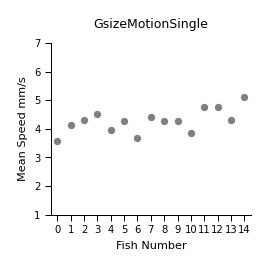

In [6]:
# Compute Euclidean distance between consecutive frames
x_shift = fish_df_long.groupby('fish_number')['x'].diff()
y_shift = fish_df_long.groupby('fish_number')['y'].diff()
fish_df_long['speed'] = np.sqrt(x_shift**2 + y_shift**2)

# Scale speed by the frame rate and conversion factor
fish_df_long['scaled_speed'] = fish_df_long['speed'] * framerate / PX_TO_MM

# Compute mean and standard error for each fish
summary_df = fish_df_long.groupby('fish_number')['scaled_speed'].agg(['mean', 'sem']).reset_index()

# Plotting
FIG_W_IN = 1 * PANEL_H_MM * MM_TO_IN
plt.figure(figsize=(FIG_W_IN, FIG_H_IN))
sns.pointplot(data=summary_df, x='fish_number', y='mean', capsize=0.2, legend=False, linestyles="", color='gray')
plt.title(experiment)
plt.xlabel("Fish Number")
plt.ylabel("Mean Speed mm/s")
plt.ylim(1, 7)
plt.show()

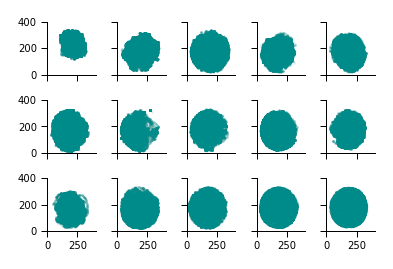

In [7]:
n_fish = fish_df_long['fish_number'].nunique()
FIG_W_IN = 1.5 * PANEL_H_MM * MM_TO_IN
fig, axes = plt.subplots(nrows=3, ncols=5, figsize=(FIG_W_IN, FIG_H_IN), sharex=True, sharey=True)
axes = axes.ravel()

for f in range(n_fish):
    ax = axes[f]
    filtered_df = fish_df_long[(fish_df_long['fish_number'] == f)]
    ax.scatter(filtered_df['x'], filtered_df['y'], s=1, alpha=.03, color='darkcyan')
    ax.set_xlim(0, 400)
    ax.set_ylim(0, 400)

plt.show()

/var/folders/vw/c25xvnd9261_m9fn18n8vf040000gn/T/ipykernel_8965/3173566600.py:40: UserWarning: The figure layout has changed to tight
  plt.tight_layout(rect=[0, 0, 0.9, 1])


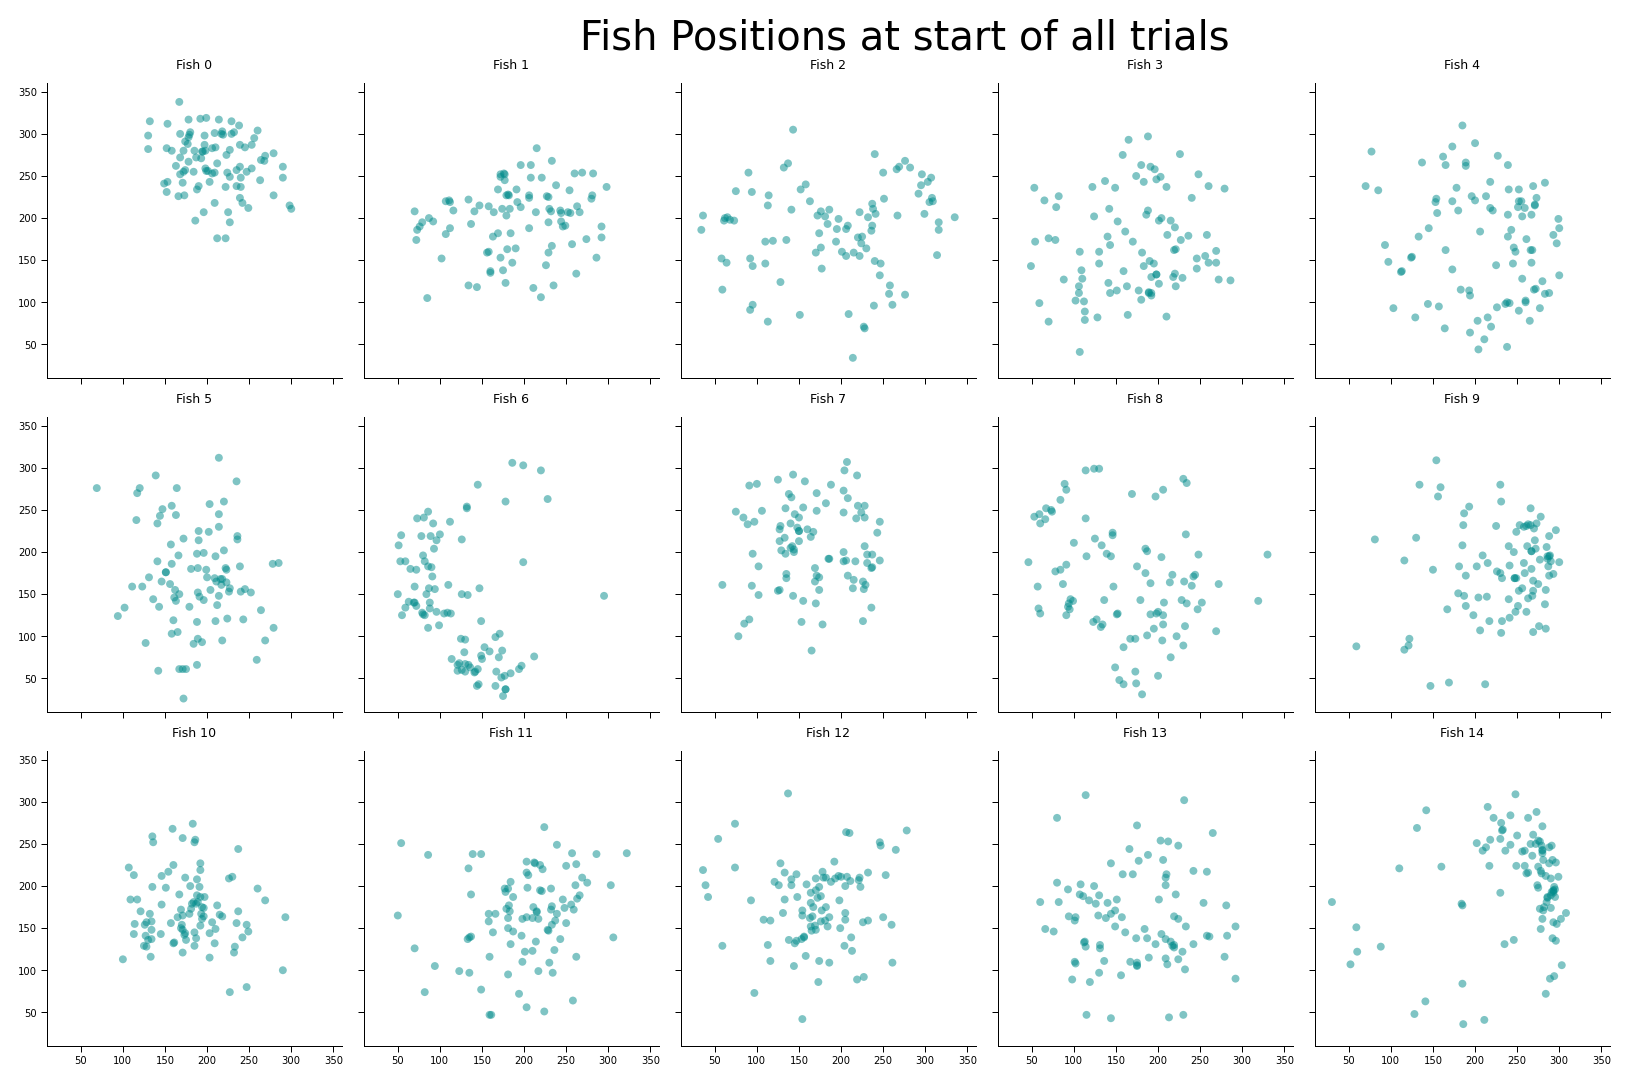

In [10]:
# 1. Subset to trial start & left‐side
df0 = fish_df_long[
    (fish_df_long['frame_count_stimulus'] == 0) &
    (fish_df_long['stimulus'] != 'inter_stim_pause')].copy()

# 2. Compute global limits
x_min, x_max = df0['x'].min(), df0['x'].max()
y_min, y_max = df0['y'].min(), df0['y'].max()

# 3. Fish list & subplot grid
fish_ids = sorted(df0['fish_number'].unique())
ncols = 5
nrows = int(np.ceil(len(fish_ids) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(10, 2 * nrows),
                         sharex=True, sharey=True)
axes_flat = axes.flatten()

# 4. Plot scatter for each fish
for ax, fish in zip(axes_flat, fish_ids):
    sub = df0[df0['fish_number'] == fish]
    ax.scatter(sub['x'], sub['y'],
               s=10,          # marker size
               alpha=0.5, # semi‐transparent
               color='darkcyan',
               edgecolor='none')

    ax.set_title(f'Fish {fish}')
    ax.set_aspect('equal')
    ax.set_xlim(10, 360)
    ax.set_ylim(10, 360)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# 5. Turn off unused axes
for ax in axes_flat[len(fish_ids):]:
    ax.axis('off')

fig.suptitle('Fish Positions at start of all trials', fontsize=16)
plt.tight_layout(rect=[0, 0, 0.9, 1])
plt.show()

#### Example fish and dots trajectory


In [11]:
TRIAL = 1
FISH = 'f0'
frames_before = 300
seconds_display = 30
n_stimuli = 8

sel_fish_df = fish_data_abs[FISH]

# Filter the DataFrame for fish 0, trial 1, and stimulus_block 2
filtered_df = sel_fish_df[(sel_fish_df['trial_id'] == TRIAL) &
                          (sel_fish_df['stimulus_block_id'] == (TRIAL*2)) &
                          (sel_fish_df['frame_count_stimulus'] <= (seconds_display * framerate))]

# Get the frame numbers for the selected data
selected_frames = filtered_df['frame']

# Filter the DataFrame for the 200 frames before the selected frames

previous_frames_df = sel_fish_df[(sel_fish_df['frame'] >= (min(selected_frames) - frames_before)) &
                                 (sel_fish_df['frame'] < min(selected_frames))]

#stim_trial_df = stim_ego_dict[f'f{FISH}'][stim_ego_dict[f'f{FISH}']['frame'].isin(filtered_df['frame'])]

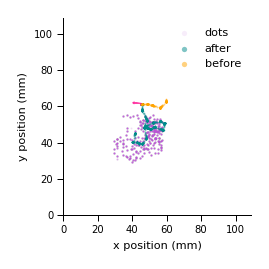

In [12]:
# create same plot as before but in mm 
# Create the scatter plot
FIG_W_IN = 1 * PANEL_H_MM * MM_TO_IN
fig, ax = plt.subplots(figsize=(FIG_W_IN, FIG_H_IN))
# Plot dots first (lower layer)
for dot in range(n_stimuli):
    if dot == 0:
        ax.scatter(filtered_df[f'd{dot}_x'] / PX_TO_MM, filtered_df[f'd{dot}_y'] / PX_TO_MM, s=0.5, alpha=.1, color='mediumorchid', label="dots", zorder=1)
    else:
        ax.scatter(filtered_df[f'd{dot}_x'] / PX_TO_MM, filtered_df[f'd{dot}_y'] / PX_TO_MM, s=0.5, alpha=.1, color='mediumorchid', zorder=1)
# Plot the filtered data (frames from the stimulus)
ax.scatter(filtered_df['x'] / PX_TO_MM, filtered_df['y'] / PX_TO_MM, s=0.5, alpha=.5, color='darkcyan', label="after", zorder=2)
# Plot the previous frames (frames before the stimulus)
ax.scatter(previous_frames_df['x'] / PX_TO_MM, previous_frames_df['y'] / PX_TO_MM, s=0.5, alpha=.5, color='orange', label="before", zorder=2)
# Convert orientation to radians and compute direction vector
ori_rad_t0 = filtered_df['theta'].iloc[0]
dx, dy = np.cos(ori_rad_t0), np.sin(ori_rad_t0)
arrow_length = 4  # Adjust length if needed
# Add a small orientation line (higher layer)
ax.arrow(filtered_df['x'].iloc[0] / PX_TO_MM, filtered_df['y'].iloc[0] / PX_TO_MM, dx * arrow_length, dy * arrow_length, 
         fc='deeppink', ec='deeppink', alpha=0.8, zorder=3, head_width=1, head_length=1, linewidth=0.5)
# Formatting
ax.invert_yaxis()
ax.set_xlabel('x position (mm)')
ax.set_ylabel('y position (mm)')
ax.set_xlim(0, 400 / PX_TO_MM)
ax.set_ylim(0, 400 / PX_TO_MM)
ax.legend(bbox_to_anchor=(1, 1), markerscale=3, frameon=False)
fig.savefig(plot_path / f"{FIGURE}e_semicl_example_traj.svg")
fig.savefig(plot_path / f"{FIGURE}e_semicl_example_traj.pdf")
plt.show()

Plot fish position rotated

In [13]:
sel_fish_df = fish_data_rot[FISH]

# Filter the DataFrame for fish 0, trial 1, and stimulus_block 2
filtered_df = sel_fish_df[(sel_fish_df['trial_id'] == TRIAL) &
                          (sel_fish_df['stimulus_block_id'] == (TRIAL*2)) &
                          (sel_fish_df['frame_count_stimulus'] <= (seconds_display * framerate))]

# Get the frame numbers for the selected data
selected_frames = filtered_df['frame']

# Filter the DataFrame for the 200 frames before the selected frames
previous_frames_df = sel_fish_df[(sel_fish_df['frame'] >= (min(selected_frames) - frames_before)) &
                                 (sel_fish_df['frame'] < min(selected_frames))]

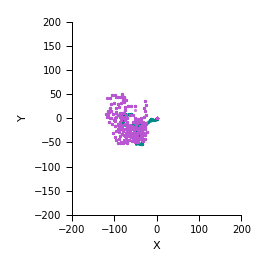

In [14]:
# Create the scatter plot
FIG_W_IN = 1 * PANEL_H_MM * MM_TO_IN
fig, ax = plt.subplots(figsize=(FIG_W_IN, FIG_H_IN))

# Plot the filtered data (frames from the stimulus)
ax.scatter(filtered_df['x'], filtered_df['y'], s=1.5, alpha=.8, color='darkcyan')

##TODO currently previous frames are part of previous stimulus

for dot in range(n_stimuli):
    ax.scatter(filtered_df[f'd{dot}_x'], filtered_df[f'd{dot}_y'], s=1.5, alpha=.5, color='mediumorchid')

# Formatting
ax.invert_yaxis()
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_xlim(-200, 200)
ax.set_ylim(-200, 200)

plt.show()

#### Distance fish vs nearest dot at time 0 

In [15]:
# Nearest dot distance at stimulus start (frame just before frame_count_stimulus == 0)
# using ego coordinates for each fish
nearest_dot_t0_per_fish = {}

for fish_id, df in fish_data_ego.items():
    df0 = df[(df['frame_count_stimulus'] == 0) &
             (df['stimulus'] != 'inter_stim_pause')].copy()

    # Use the frame immediately before the stimulus frame
    df0 = df0.assign(frame_prev=df0['frame'] - 1)
    df_prev = df[df['frame'].isin(df0['frame_prev'])].copy()
    df_prev = df_prev.rename(columns={'frame': 'frame_prev'})
    df0 = df0.merge(df_prev, on='frame_prev', suffixes=('_t0', ''))

    dist_cols = []
    for dot in range(n_stimuli):
        dx = df0[f'd{dot}_x'] - df0['x']
        dy = df0[f'd{dot}_y'] - df0['y']
        dist_cols.append(np.sqrt(dx**2 + dy**2).to_numpy())

    dist_mat = np.column_stack(dist_cols)
    n_dots = (df0['n_dots_left'] + df0['n_dots_right']).to_numpy()
    n_dots = np.clip(n_dots, 0, n_stimuli).astype(int)

    mask = np.arange(n_stimuli)[None, :] >= n_dots[:, None]
    dist_mat[mask] = np.inf
    nearest = dist_mat.min(axis=1)
    nearest[n_dots == 0] = np.nan

    if 'trial_id' in df0.columns:
        df0 = df0.assign(nearest_dot=nearest).sort_values('trial_id')
        nearest = df0.groupby('trial_id', sort=False)['nearest_dot'].first().to_numpy()

    nearest_dot_t0_per_fish[fish_id] = nearest


In [16]:
# Average nearest-dot distance at stimulus start across stimuli
n_fish = fish_df_long['fish_number'].nunique()
rows = []

for fish in range(n_fish):
    mask = (
        (fish_df_long['frame_count_stimulus'] == 0) &
        (fish_df_long['stimulus'] != 'inter_stim_pause') &
        #(fish_df_long['dots_out'] < 1) &
        (fish_df_long['fish_number'] == fish)
    )
    df_fish = fish_df_long[mask].copy()

    trials = sorted(df_fish['trial_id'].unique())
    nearest = nearest_dot_t0_per_fish.get(f'f{fish}')

    if len(trials) != len(nearest):
        print(f"f{fish}: trial mismatch (trials={len(trials)}, nearest={len(nearest)})")
        continue

    trial_to_nearest = dict(zip(trials, nearest))
    df_fish['nearest_dot'] = df_fish['trial_id'].map(trial_to_nearest)
    mask = df_fish['dots_out'] < 1
    df_fish = df_fish[mask]

    avg_by_stim = df_fish.groupby('stimulus', sort=False)['nearest_dot'].mean().reset_index()
    avg_by_stim['fish_number'] = fish
    rows.append(avg_by_stim)

avg_nearest_by_stim = pd.concat(rows, ignore_index=True)

stim_order = ['d1s0', 'd1s3.5', 'd2s3.5', 'd4s0', 'd4s3.5', 'd6s3.5', 'd8s0', 'd8s3.5']

avg_nearest_by_stim['stimulus'] = pd.Categorical(
    avg_nearest_by_stim['stimulus'],
    categories=stim_order,
    ordered=True
)

summary = (avg_nearest_by_stim
           .groupby('stimulus')['nearest_dot']
           .agg(['mean', 'sem'])
           .reset_index())


/var/folders/vw/c25xvnd9261_m9fn18n8vf040000gn/T/ipykernel_8965/3725647682.py:41: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby('stimulus')['nearest_dot']


/var/folders/vw/c25xvnd9261_m9fn18n8vf040000gn/T/ipykernel_8965/3448113159.py:29: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


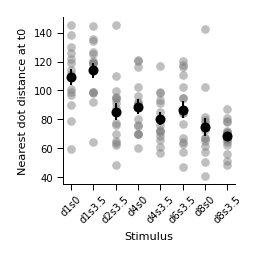

In [17]:
FIG_W_IN = 1 * PANEL_H_MM * MM_TO_IN
fig, ax = plt.subplots(figsize=(FIG_W_IN, FIG_H_IN))

# Ensure ordered categorical for plotting
stim_order = ['d1s0', 'd1s3.5', 'd2s3.5', 'd4s0', 'd4s3.5', 'd6s3.5', 'd8s0', 'd8s3.5']

plot_df = avg_nearest_by_stim.copy()
plot_df['stimulus'] = pd.Categorical(plot_df['stimulus'], categories=stim_order, ordered=True)
summary_plot = summary.copy()
summary_plot['stimulus'] = pd.Categorical(summary_plot['stimulus'], categories=stim_order, ordered=True)

# Scatter each fish (behind mean)
for fish in range(n_fish):
    df_plot = plot_df[plot_df['fish_number'] == fish].sort_values('stimulus')
    ax.scatter(df_plot['stimulus'], df_plot['nearest_dot'],
               alpha=0.5, s=12, color='gray')

# Mean + SEM
summary_plot = summary_plot.sort_values('stimulus')
ax.errorbar(summary_plot['stimulus'], summary_plot['mean'], yerr=summary_plot['sem'],
            fmt='o', color='black', capsize=0, markersize=3, linewidth=.8)

ax.set_xlabel('Stimulus')
ax.set_ylabel('Nearest dot distance at t0')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


#### Distance fish - dots over time

In [33]:
def parse_stim(stim):
    """
    'd1s3.5' -> (1, 3.5). Returns (None, None) for non-matching strings.
    """
    m = re.match(r"d(\d+)s([\d\.]+)$", stim)
    if not m:
        return None, None
    return int(m.group(1)), float(m.group(2))

def is_motion(stim):
    d, s = parse_stim(stim)
    return d is not None and s is not None and s != 0.0

def is_static(stim):
    d, s = parse_stim(stim)
    return d is not None and s is not None and s == 0.0

def auto_label(stim):
    if stim == "inter_stim_pause":
        return "control"
    d, s = parse_stim(stim)
    if d is None:
        return stim
    return f"{d} - {'static' if s == 0 else 'motion'}"

# Use your order
stimuli_order = ["d1s3.5", "d2s3.5", "d4s3.5", "d6s3.5", "d8s3.5", "d1s0", "d4s0", "d8s0", "inter_stim_pause"]

# ---------------------------
# 2) Build gradient palettes
# ---------------------------
MOTION_CMAP = "RdPu"   # e.g., "PuBu", "Blues", "Purples", "viridis", add "_r" to reverse
STATIC_CMAP = "Oranges"   # e.g., "OrRd", "YlOrRd", "Reds", "magma", add "_r" to reverse

motion_stims = [s for s in stimuli_order if is_motion(s)]
static_stims = [s for s in stimuli_order if is_static(s)]

motion_dots_sorted = sorted({parse_stim(s)[0] for s in motion_stims})
static_dots_sorted = sorted({parse_stim(s)[0] for s in static_stims})

motion_palette = sns.color_palette(MOTION_CMAP, n_colors=len(motion_dots_sorted)) if motion_dots_sorted else []
static_palette = sns.color_palette(STATIC_CMAP, n_colors=len(static_dots_sorted)) if static_dots_sorted else []

# Map each stimulus to the gradient color by rank of its dot count
color_map = {}
dot_to_motion_color = {d: motion_palette[i] for i, d in enumerate(motion_dots_sorted)}
dot_to_static_color = {d: static_palette[i] for i, d in enumerate(static_dots_sorted)}

for s in motion_stims:
    d, _ = parse_stim(s)
    color_map[s] = dot_to_motion_color[d]
for s in static_stims:
    d, _ = parse_stim(s)
    color_map[s] = dot_to_static_color[d]
color_map["inter_stim_pause"] = "gray"

# Optional: if you have a custom label map already, use it; otherwise fall back to auto_label
def get_label(stim):
    try:
        return stim_label_map.get(stim, auto_label(stim))  # uses your existing dict if present
    except NameError:
        return auto_label(stim)


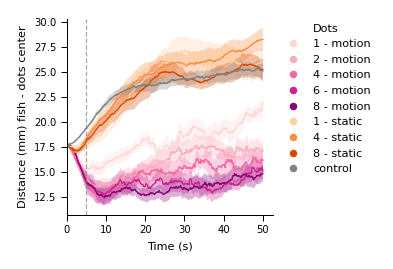

In [ ]:

FIG_W_IN = 1.5 * PANEL_H_MM * MM_TO_IN
fig, ax = plt.subplots(figsize=(FIG_W_IN, FIG_H_IN))

for stim in stimuli_order:
    # Filter data for the current stim across all fish
    stim_data = fish_df_long[(fish_df_long['stimulus'] == stim) &
                             (fish_df_long['dots_out'] < 1)].copy()

    # Convert and time index
    stim_data.loc[:, 'dist_mm'] = stim_data['squareDist_rot'] / PX_TO_MM
    stim_data.loc[:, 'time'] = stim_data['frame_count_stimulus'] / framerate

    # Avg per fish per time (across trials)
    fish_time_avg = stim_data.groupby(['fish_number', 'time'])['dist_mm'].mean().reset_index()

    # Mean ± SEM across fish at each time
    grouped = fish_time_avg.groupby('time')['dist_mm']
    avg = grouped.mean()
    sem = grouped.sem()

    # Color + plot
    color = color_map.get(stim, 'gray')
    label = get_label(stim)

    #cut until 50 seconds
    avg = avg[avg.index <= 50]
    sem = sem[sem.index <= 50]

    ax.plot(avg.index, avg, label=label, color=color)
    ax.fill_between(avg.index, avg - sem, avg + sem, alpha=0.3, color=color, edgecolor='none')

ax.axvline(5, linestyle='--', linewidth=.5, color='grey', alpha=0.7)
#ax.text(8, 25, '5 s', ha='center', va='bottom', color='grey')

# Axes styling
ax.set_xlabel('Time (s)')
ax.set_ylabel('Distance (mm) fish - dots center')
ax.set_xlim(left=0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Legend outside on the right, use circle-only markers
legend_handles = []
for stim in stimuli_order:
    color = color_map.get(stim, 'gray')
    label = get_label(stim)
    legend_handles.append(
        Line2D([0], [0], marker='o', color=color, linestyle='None', markersize=2, label=label)
    )

ax.legend(handles=legend_handles, title='Dots', loc='upper left',
          bbox_to_anchor=(1.02, 1), borderaxespad=0., frameon=False)

fig.savefig(plot_path / f"{FIGURE}c_dist_fish_dots.svg")
fig.savefig(plot_path / f"{FIGURE}c_dist_fish_dots.pdf")
plt.show()


In [ ]:

from scipy import stats as scipy_stats

FIG_W_IN = 1.5 * PANEL_H_MM * MM_TO_IN
fig, ax = plt.subplots(figsize=(FIG_W_IN, FIG_H_IN))

for stim in stimuli_order:
    # Filter data for the current stim across all fish
    stim_data = fish_df_long[(fish_df_long['stimulus'] == stim) &
                             (fish_df_long['dots_out'] < 1)].copy()

    # Convert and time index
    stim_data.loc[:, 'dist_mm'] = stim_data['squareDist_rot'] / PX_TO_MM
    stim_data.loc[:, 'time'] = stim_data['frame_count_stimulus'] / framerate

    # Avg per fish per time (across trials)
    fish_time_avg = stim_data.groupby(['fish_number', 'time'])['dist_mm'].mean().reset_index()

    # Mean and 95% CI across fish at each time
    grouped = fish_time_avg.groupby('time')['dist_mm']
    avg = grouped.mean()
    sem = grouped.sem()
    n = grouped.count()
    ci95 = sem * scipy_stats.t.ppf(0.975, n - 1)

    # Color + plot
    color = color_map.get(stim, 'gray')
    label = get_label(stim)

    # cut until 50 seconds
    avg = avg[avg.index <= 50]
    ci95 = ci95[ci95.index <= 50]

    ax.plot(avg.index, avg, label=label, color=color)
    ax.fill_between(avg.index, avg - ci95, avg + ci95, alpha=0.3, color=color, edgecolor='none')

ax.axvline(5, linestyle='--', linewidth=.5, color='grey', alpha=0.7)

# Axes styling
ax.set_xlabel('Time (s)')
ax.set_ylabel('Distance (mm) fish - dots center')
ax.set_xlim(left=0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Legend outside on the right, use circle-only markers
legend_handles = []
for stim in stimuli_order:
    color = color_map.get(stim, 'gray')
    label = get_label(stim)
    legend_handles.append(
        Line2D([0], [0], marker='o', color=color, linestyle='None', markersize=2, label=label)
    )

ax.legend(handles=legend_handles, title='Dots', loc='upper left',
          bbox_to_anchor=(1.02, 1), borderaxespad=0., frameon=False)

fig.savefig(plot_path / f"{FIGURE}c_dist_fish_dots_ci95.svg")
fig.savefig(plot_path / f"{FIGURE}c_dist_fish_dots_ci95.pdf")
plt.show()


In [35]:
# for each fish and each stimulus, calculate the number of valid trials (dots_out < 1)
trial_counts = (fish_df_long[(fish_df_long['dots_out'] < 1) & (fish_df_long['stimulus'] != 'inter_stim_pause')]
                .groupby(['fish_number', 'stimulus'])['trial_id']
                .nunique()
                .reset_index(name='valid_trial_count'))

# Display the trial counts
print(trial_counts)

     fish_number stimulus  valid_trial_count
0              0     d1s0                  8
1              0   d1s3.5                 12
2              0   d2s3.5                 12
3              0     d4s0                  8
4              0   d4s3.5                 12
..           ...      ...                ...
115           14     d4s0                 10
116           14   d4s3.5                 11
117           14   d6s3.5                 10
118           14     d8s0                  5
119           14   d8s3.5                  6

[120 rows x 3 columns]


In [ ]:
# --- parameters ---
timepoints = [0, 2, 5, 20]          # seconds
time_tol = None              # set to e.g. 1/framerate if you want a strict window instead of "nearest"

# --- build a summary table: one row per (stimulus, fish) at each timepoint ---
rows = []

for stim in stimuli_order:
    stim_data = fish_df_long[(fish_df_long['stimulus'] == stim) &
                             (fish_df_long['dots_out'] < 1)].copy()

    stim_data.loc[:, 'dist_mm'] = stim_data['squareDist_rot'] / PX_TO_MM
    stim_data.loc[:, 'time'] = stim_data['frame_count_stimulus'] / framerate

    # avg per fish per time (across trials)
    fish_time_avg = (
        stim_data
        .groupby(['fish_number', 'time'], as_index=False)['dist_mm']
        .mean()
    )

    # for each fish, pick value at each requested timepoint
    for fish, df_fish in fish_time_avg.groupby('fish_number'):
        t = df_fish['time'].to_numpy()
        y = df_fish['dist_mm'].to_numpy()

        for tp in timepoints:
            # nearest time index
            i = int(np.argmin(np.abs(t - tp)))
            t_near = float(t[i])
            y_near = float(y[i])

            # optional tolerance filter
            if (time_tol is not None) and (abs(t_near - tp) > time_tol):
                continue

            rows.append({
                'stimulus': stim,
                'fish_number': fish,
                'timepoint_s': tp,
                'time_used_s': t_near,
                'dist_mm': y_near
            })

summary_df = pd.DataFrame(rows)

# --- mean ± SEM across fish for each stimulus at each timepoint ---
stats_df = (
    summary_df
    .groupby(['timepoint_s', 'stimulus'])['dist_mm']
    .agg(mean='mean', sem='sem', n='count')
    .reset_index()
)

# Optional: keep plotting order consistent
stats_df['stimulus'] = pd.Categorical(stats_df['stimulus'], categories=stimuli_order, ordered=True)
stats_df = stats_df.sort_values(['timepoint_s', 'stimulus'])

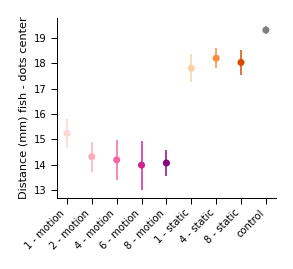

In [21]:
tp = 5
d = stats_df[stats_df['timepoint_s'] == tp].copy()
FIG_W_IN = 1.1 * PANEL_H_MM * MM_TO_IN
fig, ax = plt.subplots(figsize=(FIG_W_IN, FIG_H_IN))
x = np.arange(len(d))

for xi, mean, sem, stim in zip(x, d['mean'], d['sem'], d['stimulus']):
    c = color_map.get(stim, 'gray')
    ax.errorbar(
        xi, mean, yerr=sem,
        fmt='none',
        ecolor=c,
        linewidth=0.6,
        capsize=0,
        zorder=2
    )

# scatter points
ax.scatter(x, d['mean'],s=8,c=[color_map.get(stim, 'gray') for stim in d['stimulus']],zorder=3)

ax.set_xticks(x)
ax.set_xticklabels([get_label(s) for s in d['stimulus']],
                   rotation=45, ha='right')
ax.set_ylabel('Distance (mm) fish - dots center')
#ax.set_title('5 s')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

fig.savefig(plot_path / f"{FIGURE}d_dist_fish_dots_5s.svg")
fig.savefig(plot_path / f"{FIGURE}d_dist_fish_dots_5s.pdf")
plt.show()


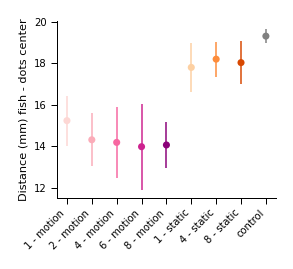

In [27]:
from scipy import stats as scipy_stats

tp = 5
d = stats_df[stats_df['timepoint_s'] == tp].copy()
d['ci95'] = d['sem'] * scipy_stats.t.ppf(0.975, d['n'] - 1)

FIG_W_IN = 1.1 * PANEL_H_MM * MM_TO_IN
fig, ax = plt.subplots(figsize=(FIG_W_IN, FIG_H_IN))
x = np.arange(len(d))

for xi, mean, ci95, stim in zip(x, d['mean'], d['ci95'], d['stimulus']):
    c = color_map.get(stim, 'gray')
    ax.errorbar(
        xi, mean, yerr=ci95,
        fmt='none',
        ecolor=c,
        linewidth=0.6,
        capsize=0,
        zorder=2
    )

# scatter points
ax.scatter(x, d['mean'], s=8, c=[color_map.get(stim, 'gray') for stim in d['stimulus']], zorder=3)

ax.set_xticks(x)
ax.set_xticklabels([get_label(s) for s in d['stimulus']],
                   rotation=45, ha='right')
ax.set_ylabel('Distance (mm) fish - dots center')
#ax.set_title('5 s')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

fig.savefig(plot_path / f"{FIGURE}g_dist_fish_dots_5s_ci95.svg")
fig.savefig(plot_path / f"{FIGURE}g_dist_fish_dots_5s_ci95.pdf")
plt.show()


In [38]:
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from scipy import stats

# ---- choose timepoint and control name ----
tp = 5  # or 30
control = "inter_stim_pause"

# ---- fish-level table at that timepoint (one row per fish per stimulus) ----
d = summary_df.loc[summary_df["timepoint_s"] == tp, ["fish_number", "stimulus", "dist_mm"]].dropna().copy()

# make control the reference category
cats = [control] + [c for c in d["stimulus"].unique() if c != control]
d["stimulus"] = pd.Categorical(d["stimulus"], categories=cats, ordered=True)

# ---- one-way ANOVA ----
model = smf.ols("dist_mm ~ C(stimulus)", data=d).fit()
anova_table = sm.stats.anova_lm(model, typ=2)
print(anova_table)

rows = []
df_resid = model.df_resid

for g in cats[1:]:  # skip control
    term = f"C(stimulus)[T.{g}]"
    if term not in model.params:
        continue

    diff = model.params[term]      # mean(group) - mean(control)
    se = model.bse[term]
    tval = diff / se
    pval = 2 * (1 - stats.t.cdf(abs(tval), df_resid))

    rows.append([g, diff, tval, pval])

posthoc = pd.DataFrame(
    rows, columns=["group", "diff_vs_control", "t", "p"]
)

posthoc["p_adj"] = multipletests(posthoc["p"], method="holm")[1]
posthoc = posthoc.sort_values("p_adj")

print(posthoc)



                 sum_sq     df          F        PR(>F)
C(stimulus)  565.895720    8.0  13.016299  1.482938e-13
Residual     684.745908  126.0        NaN           NaN
    group  diff_vs_control         t             p         p_adj
3  d6s3.5        -5.340407 -6.273726  5.183268e-09  4.146615e-08
4  d8s3.5        -5.257043 -6.175793  8.356025e-09  5.849217e-08
2  d4s3.5        -5.133047 -6.030126  1.688515e-08  1.013109e-07
1  d2s3.5        -5.006281 -5.881207  3.435640e-08  1.717820e-07
0  d1s3.5        -4.081831 -4.795194  4.502473e-06  1.800989e-05
5    d1s0        -1.511506 -1.775666  7.820211e-02  2.346063e-01
6    d4s0        -1.112332 -1.306730  1.936845e-01  2.705698e-01
7    d8s0        -1.279591 -1.503219  1.352849e-01  2.705698e-01


#### Ratio time close to dots across group size

In [28]:
stimuli_35 = ["d1s3.5", "d2s3.5", "d4s3.5", "d6s3.5", "d8s3.5"]
stimuli_0 = ["d1s0", "d4s0", "d8s0"]
stimuli = stimuli_35 + stimuli_0 + ['inter_stim_pause']
stim_sides = ['L', 'R']  # Both sides

stim_labels = {}
for stim in stimuli:
    if stim == 'inter_stim_pause':
        stim_labels[stim] = 'control'
    else:
        dot_num = stim.split('s')[0].replace('d', '')  # e.g., 'd1' -> '1'
        speed = stim.split('s')[1]
        motion_label = 'motion' if speed != '0' else 'static'
        stim_labels[stim] = dot_num

lr_ratios_per_stim_side = {}

for stim in stimuli:
    for side in stim_sides:
        stim_data = fish_df_long[(fish_df_long['stimulus'] == stim) &
                                 (fish_df_long['stim_side'] == side)].copy()

        # Masks
        left_mask = stim_data['x_rot'] < 0
        right_mask = stim_data['x_rot'] > 0

        # Time per trial per fish
        left_time = stim_data[left_mask].groupby(['fish_number', 'trial_id']).size() / framerate
        right_time = stim_data[right_mask].groupby(['fish_number', 'trial_id']).size() / framerate

        # Average per fish
        left_avg = left_time.groupby('fish_number').mean()
        right_avg = right_time.groupby('fish_number').mean()

        # LR ratio
        lr_ratio = (left_avg - right_avg) / (left_avg + right_avg)
        lr_ratios_per_stim_side[(stim, side)] = lr_ratio

# Color palettes
motion_palette = sns.color_palette("PiYG", n_colors=len(stimuli_35) * 2 + 5)
static_palette = sns.color_palette("RdBu", n_colors=len(stimuli_0) * 2)

left_m_palette = sns.color_palette('Greens', n_colors=len(stimuli_35)+1)
right_m_palette = sns.color_palette('Blues', n_colors=len(stimuli_35)+1)

left_s_palette = sns.color_palette('Reds', n_colors=len(stimuli_0)+1)
right_s_palette = sns.color_palette('Purples', n_colors=len(stimuli_0)+1)

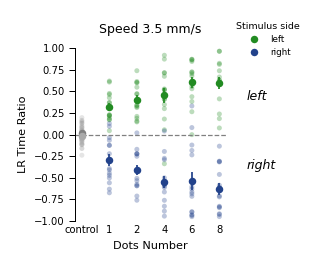

In [29]:
FIG_W_IN = 1.2 * PANEL_H_MM * MM_TO_IN

fig, ax = plt.subplots(figsize=(FIG_W_IN, FIG_H_IN))
stimuli = ['inter_stim_pause'] + stimuli_35
x = np.arange(len(stimuli))

for i, stim in enumerate(stimuli):
    for side in stim_sides:
        y = lr_ratios_per_stim_side.get((stim, side), pd.Series(dtype=float))

        if side == 'L':
            base_color = "#228B22" 
        else:
            base_color = "#22428B"
        
        if stim == 'inter_stim_pause':
            if side == 'L':
                base_color = 'gray'
            else:
                base_color = 'darkgray'

        ax.scatter([x[i]] * len(y), y, color=base_color, edgecolor='none', alpha=.3, s=4)
        ax.errorbar(x[i], y.mean(), yerr=y.sem(), fmt='o', color=base_color,
                    capsize=0, elinewidth=0.7, markeredgecolor=base_color, markersize=2)

#add legend 
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='left', markerfacecolor="#228B22", markersize=4),
    Line2D([0], [0], marker='o', color='w', label='right', markerfacecolor="#22428B", markersize=4)
]
ax.legend(handles=legend_elements, bbox_to_anchor=(1.54, 1.2),
        loc='upper right', frameon=False, title='Stimulus side', title_fontsize=3.8, fontsize=3.5)

#Add text for left and right
ax.text(6, 0.4, 'left', fontsize=5,fontstyle="italic", ha="left")
ax.text(6, -0.4, 'right', fontsize=5,fontstyle="italic", ha="left")

# Aesthetics
ax.axhline(0, linestyle='--', color='gray')
ax.set_xticks(x)
ax.set_xticklabels([stim_labels[stim] for stim in stimuli], ha='center')
ax.tick_params(axis='x', length=0)
ax.set_ylabel("LR Time Ratio")
ax.set_ylim(-1, 1)
ax.set_title("Speed 3.5 mm/s")
ax.set_xlabel("Dots Number")
ax.spines['bottom'].set_visible(False)

fig.savefig(plot_path / f"{FIGURE}e_LRratio_motion.svg")
fig.savefig(plot_path / f"{FIGURE}e_LRratio_motion.pdf")
plt.show()

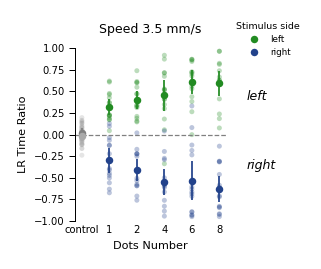

In [30]:
from scipy import stats as scipy_stats

FIG_W_IN = 1.2 * PANEL_H_MM * MM_TO_IN

fig, ax = plt.subplots(figsize=(FIG_W_IN, FIG_H_IN))
stimuli = ['inter_stim_pause'] + stimuli_35
x = np.arange(len(stimuli))

for i, stim in enumerate(stimuli):
    for side in stim_sides:
        y = lr_ratios_per_stim_side.get((stim, side), pd.Series(dtype=float))
        n = y.count()
        ci95 = y.sem() * scipy_stats.t.ppf(0.975, n - 1) if n > 1 else np.nan

        if side == 'L':
            base_color = "#228B22" 
        else:
            base_color = "#22428B"
        
        if stim == 'inter_stim_pause':
            if side == 'L':
                base_color = 'gray'
            else:
                base_color = 'darkgray'

        ax.scatter([x[i]] * len(y), y, color=base_color, edgecolor='none', alpha=.3, s=4)
        ax.errorbar(x[i], y.mean(), yerr=ci95, fmt='o', color=base_color,
                    capsize=0, elinewidth=0.7, markeredgecolor=base_color, markersize=2)

#add legend 
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='left', markerfacecolor="#228B22", markersize=4),
    Line2D([0], [0], marker='o', color='w', label='right', markerfacecolor="#22428B", markersize=4)
]
ax.legend(handles=legend_elements, bbox_to_anchor=(1.54, 1.2),
        loc='upper right', frameon=False, title='Stimulus side', title_fontsize=3.8, fontsize=3.5)

#Add text for left and right
ax.text(6, 0.4, 'left', fontsize=5,fontstyle="italic", ha="left")
ax.text(6, -0.4, 'right', fontsize=5,fontstyle="italic", ha="left")

# Aesthetics
ax.axhline(0, linestyle='--', color='gray')
ax.set_xticks(x)
ax.set_xticklabels([stim_labels[stim] for stim in stimuli], ha='center')
ax.tick_params(axis='x', length=0)
ax.set_ylabel("LR Time Ratio")
ax.set_ylim(-1, 1)
ax.set_title("Speed 3.5 mm/s")
ax.set_xlabel("Dots Number")
ax.spines['bottom'].set_visible(False)

fig.savefig(plot_path / f"{FIGURE}e_LRratio_motion_ci95.svg")
fig.savefig(plot_path / f"{FIGURE}e_LRratio_motion_ci95.pdf")
plt.show()

In [31]:
rows = []

for stim in stimuli_35:  # static only (speed = 0)
    dot_number = int(stim.split('s')[0].replace('d', ''))

    lri_L = lr_ratios_per_stim_side[(stim, 'L')].abs()
    lri_R = lr_ratios_per_stim_side[(stim, 'R')].abs()

    # one value per fish per stimulus: mean(|LRI|) across L and R presentations
    abs_LRI = pd.concat([lri_L, lri_R], axis=1).mean(axis=1)

    for fish, val in abs_LRI.items():
        rows.append({
            "fish_number": fish,
            "dot_number": dot_number,
            "abs_LRI": val
        })

df_static = pd.DataFrame(rows)

model_static = smf.mixedlm(
    "abs_LRI ~ dot_number",
    data=df_static,
    groups=df_static["fish_number"]
).fit()

print(model_static.summary())

NameError: name 'smf' is not defined

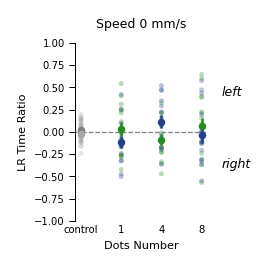

In [33]:
FIG_W_IN = 1 * PANEL_H_MM * MM_TO_IN

fig, ax = plt.subplots(figsize=(FIG_W_IN, FIG_H_IN))
stimuli = ['inter_stim_pause'] + stimuli_0
x = np.arange(len(stimuli))

for i, stim in enumerate(stimuli):
    for side in stim_sides:
        y = lr_ratios_per_stim_side.get((stim, side), pd.Series(dtype=float))

        if side == 'L':
            base_color = "#228B22" 
        else:
            base_color = "#22428B"
        
        if stim == 'inter_stim_pause':
            if side == 'L':
                base_color = 'gray'
            else:
                base_color = 'darkgray'

        ax.scatter([x[i]] * len(y), y, color=base_color, edgecolor='none', alpha=.3, s=4)
        ax.errorbar(x[i], y.mean(), yerr=y.sem(), fmt='o', color=base_color,
                    capsize=0, elinewidth=1, markeredgecolor=base_color, markersize=2)


#add legend 
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='left', markerfacecolor="#228B22", markersize=4),
    Line2D([0], [0], marker='o', color='w', label='right', markerfacecolor="#22428B", markersize=4)
]
#ax.legend(handles=legend_elements, bbox_to_anchor=(1.6, 1.2),loc='upper right', frameon=False, title='Stimulus side')

#Add text for left and right
ax.text(3.5, 0.4, 'left', fontsize=5,fontstyle="italic", ha="left")
ax.text(3.5, -0.4, 'right', fontsize=5,fontstyle="italic", ha="left")

# Aesthetics
ax.axhline(0, linestyle='--', color='grey')
ax.set_xticks(x)
ax.set_xticklabels([stim_labels[stim] for stim in stimuli], ha='center')
ax.tick_params(axis='x', length=0)
ax.set_ylabel("LR Time Ratio")
ax.set_ylim(-1, 1)
ax.set_title("Speed 0 mm/s")
ax.set_xlabel("Dots Number")
ax.spines['bottom'].set_visible(False)

fig.savefig(plot_path / f"{FIGURE}f_LRratio_static.svg")
fig.savefig(plot_path / f"{FIGURE}f_LRratio_static.pdf")
plt.show()

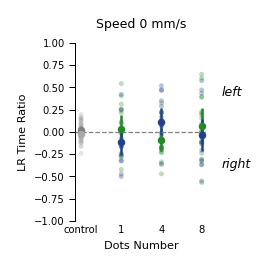

In [34]:
from scipy import stats as scipy_stats

FIG_W_IN = 1 * PANEL_H_MM * MM_TO_IN

fig, ax = plt.subplots(figsize=(FIG_W_IN, FIG_H_IN))
stimuli = ['inter_stim_pause'] + stimuli_0
x = np.arange(len(stimuli))

for i, stim in enumerate(stimuli):
    for side in stim_sides:
        y = lr_ratios_per_stim_side.get((stim, side), pd.Series(dtype=float))
        n = y.count()
        ci95 = y.sem() * scipy_stats.t.ppf(0.975, n - 1) if n > 1 else np.nan

        if side == 'L':
            base_color = "#228B22" 
        else:
            base_color = "#22428B"
        
        if stim == 'inter_stim_pause':
            if side == 'L':
                base_color = 'gray'
            else:
                base_color = 'darkgray'

        ax.scatter([x[i]] * len(y), y, color=base_color, edgecolor='none', alpha=.3, s=4)
        ax.errorbar(x[i], y.mean(), yerr=ci95, fmt='o', color=base_color,
                    capsize=0, elinewidth=1, markeredgecolor=base_color, markersize=2)


#add legend 
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='left', markerfacecolor="#228B22", markersize=4),
    Line2D([0], [0], marker='o', color='w', label='right', markerfacecolor="#22428B", markersize=4)
]
#ax.legend(handles=legend_elements, bbox_to_anchor=(1.6, 1.2),loc='upper right', frameon=False, title='Stimulus side')

#Add text for left and right
ax.text(3.5, 0.4, 'left', fontsize=5,fontstyle="italic", ha="left")
ax.text(3.5, -0.4, 'right', fontsize=5,fontstyle="italic", ha="left")

# Aesthetics
ax.axhline(0, linestyle='--', color='grey')
ax.set_xticks(x)
ax.set_xticklabels([stim_labels[stim] for stim in stimuli], ha='center')
ax.tick_params(axis='x', length=0)
ax.set_ylabel("LR Time Ratio")
ax.set_ylim(-1, 1)
ax.set_title("Speed 0 mm/s")
ax.set_xlabel("Dots Number")
ax.spines['bottom'].set_visible(False)

fig.savefig(plot_path / f"{FIGURE}f_LRratio_static_ci95.svg")
fig.savefig(plot_path / f"{FIGURE}f_LRratio_static_ci95.pdf")
plt.show()

In [43]:
rows = []

for stim in stimuli_0:  # static only (speed = 0)
    dot_number = int(stim.split('s')[0].replace('d', ''))

    lri_L = lr_ratios_per_stim_side[(stim, 'L')].abs()
    lri_R = lr_ratios_per_stim_side[(stim, 'R')].abs()

    # one value per fish per stimulus: mean(|LRI|) across L and R presentations
    abs_LRI = pd.concat([lri_L, lri_R], axis=1).mean(axis=1)

    for fish, val in abs_LRI.items():
        rows.append({
            "fish_number": fish,
            "dot_number": dot_number,
            "abs_LRI": val
        })

df_static = pd.DataFrame(rows)

model_static = smf.mixedlm(
    "abs_LRI ~ dot_number",
    data=df_static,
    groups=df_static["fish_number"]
).fit()

print(model_static.summary())

        Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: abs_LRI
No. Observations: 45      Method:             REML   
No. Groups:       15      Scale:              0.0107 
Min. group size:  3       Log-Likelihood:     28.6554
Max. group size:  3       Converged:          Yes    
Mean group size:  3.0                                
-----------------------------------------------------
             Coef. Std.Err.   z   P>|z| [0.025 0.975]
-----------------------------------------------------
Intercept    0.222    0.030 7.355 0.000  0.163  0.281
dot_number   0.006    0.005 1.106 0.269 -0.005  0.017
Group Var    0.002    0.024                          



/Users/matilde/opt/miniconda3/envs/lab/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


#### Cumulative trajectories

/var/folders/vw/c25xvnd9261_m9fn18n8vf040000gn/T/ipykernel_8965/1811273358.py:50: UserWarning: The figure layout has changed to tight
  plt.tight_layout(rect=[0, 0, 1, 0.98])  # Adjust rect to make space for the title


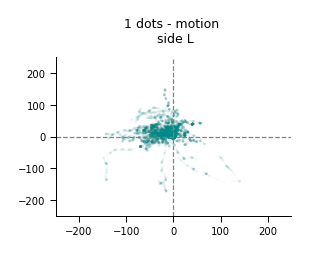

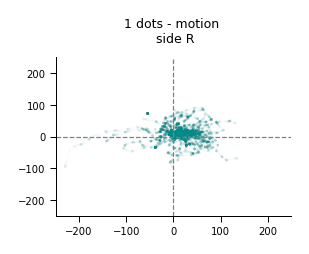

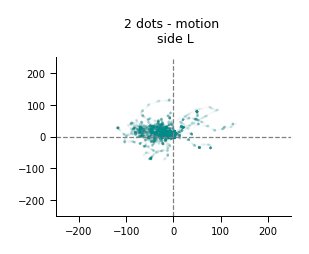

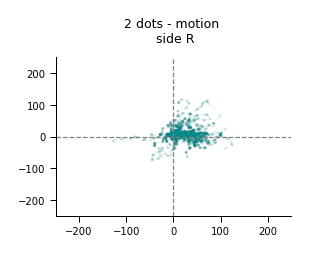

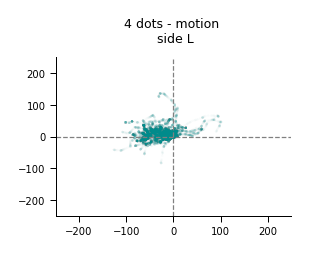

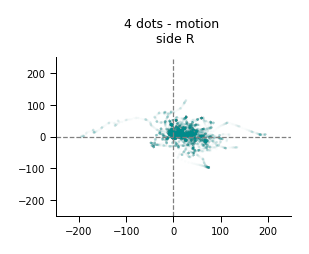

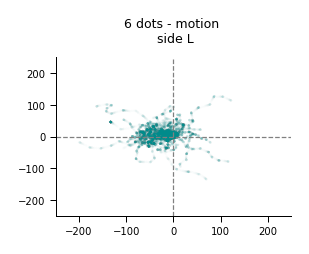

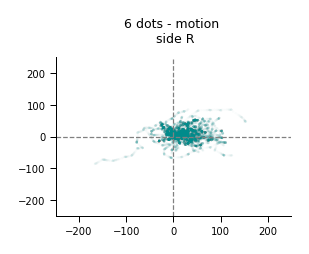

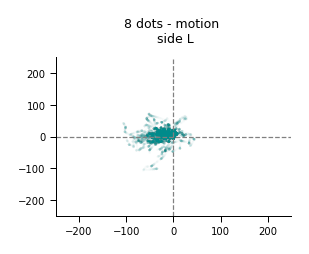

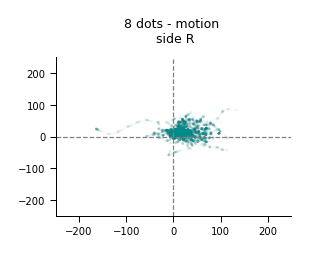

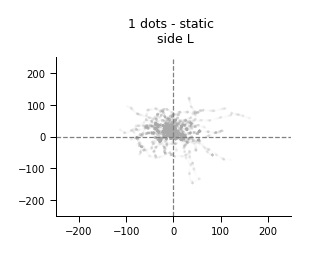

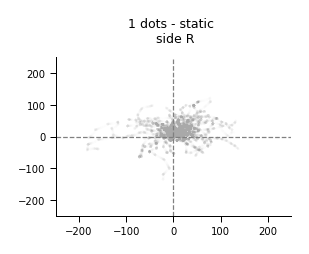

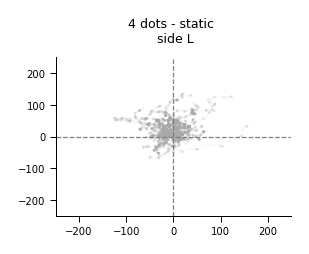

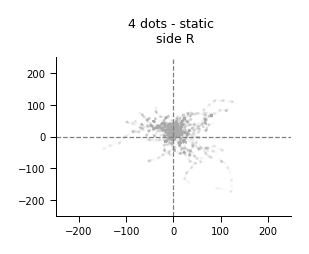

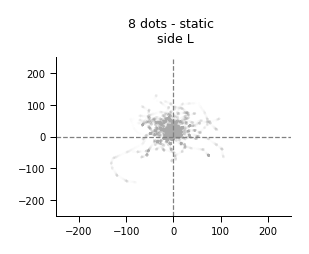

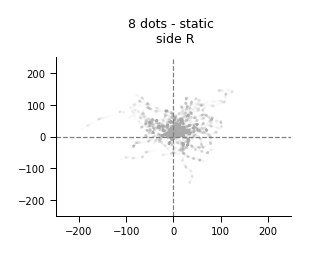

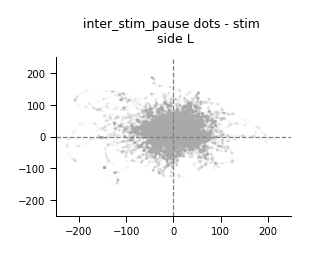

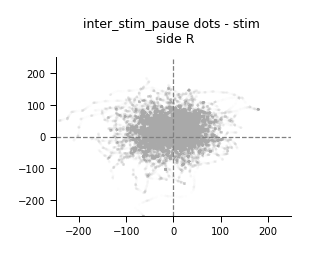

In [44]:
# Get unique conditions and stimulus sides
stimuli = ["d1s3.5", "d2s3.5", "d4s3.5", "d6s3.5", "d8s3.5", "d1s0", "d4s0", "d8s0", "inter_stim_pause"]
stim_sides = ['L', 'R']
FIG_W_IN = 1.2 * PANEL_H_MM * MM_TO_IN

# Loop over each condition and stimulus side (L and R)
for i, stim in enumerate(stimuli):
    seconds_to_display = 10
    # Filter data for the current condition
    stim_data = fish_df_long[(fish_df_long['stimulus'] == stim) &
                             (fish_df_long['frame_count_stimulus'] < seconds_to_display*framerate)].copy()

    
    # Loop through stimulus sides (L and R)
    for j, stim_side in enumerate(stim_sides):
        # Filter the data for the current stim_side
        stim_side_data = stim_data[stim_data['stim_side'] == stim_side]

        # Select the axis for the current plot (row i, column j)
        #ax = axs[i * 2 + j]
        fig, ax = fig, ax = plt.subplots(figsize=(FIG_W_IN, FIG_H_IN))
        #ax = axs[j]

        # Set title
        ndots = stim.split('d')[1][0] if stim != 'inter_stim_pause' else stim.split('d')[0]
        condition = stim_side_data["condition_grouped"].iloc[0].split('_')[1]

        color = 'darkcyan' if condition == 'motion' else 'darkgrey'

        #filter only first 10 seconds
        #stim_side_data = stim_side_data[stim_side_data['frame_count_stimulus'] <= seconds_to_display*framerate]

        # Plot the scatterplot of x_rot vs. y_rot
        ax.scatter(stim_side_data['x_rot'], stim_side_data['y_rot'], s=1, alpha=0.02, c=color)

        ax.set_title(f'{ndots} dots - {condition} \n'
                     f' side {stim_side}')

        ax.axhline(0, color='grey', linewidth=0.5, linestyle='--')
        ax.axvline(0, color='grey', linewidth=0.5, linestyle='--')

        ax.set_xlim(-250, 250)
        ax.set_ylim(-250, 250)

        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.grid(False)

        # Adjust layout to make it look neat
        plt.tight_layout(rect=[0, 0, 1, 0.98])  # Adjust rect to make space for the title

    plt.show()

NameError: name 'stim_label_map' is not defined

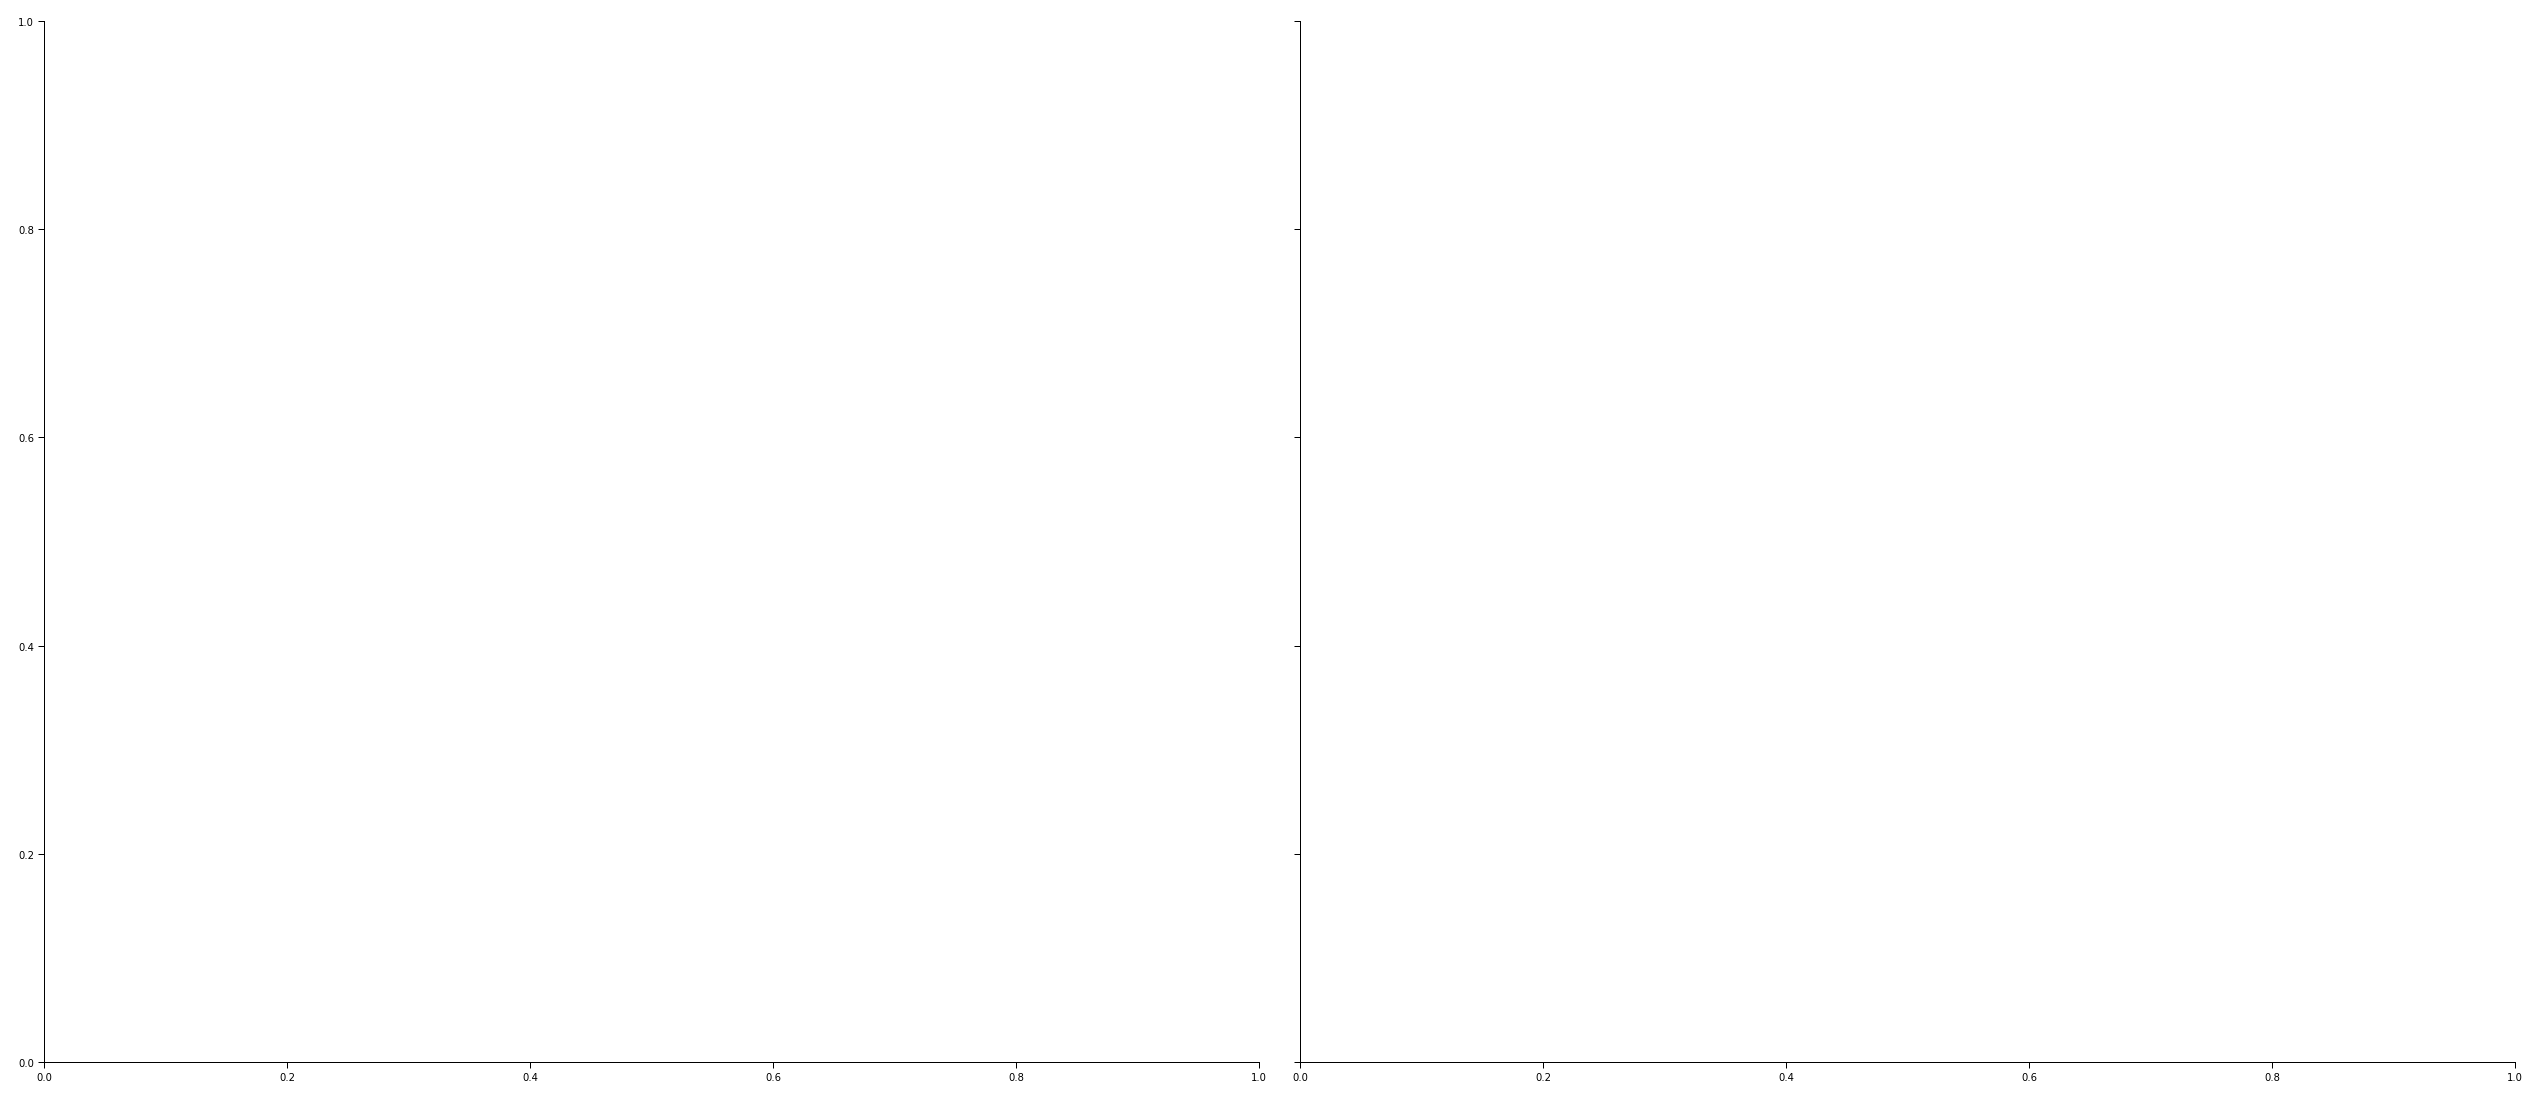

In [30]:
# Create a figure with two subplots: left for stim_side == 'L', right for stim_side == 'R'
fig, axs = plt.subplots(1, 2, figsize=(14, 6), sharey=True)  # sharey makes Y axis the same

stim_sides = ['L', 'R']

for i, stim_side in enumerate(stim_sides):
    ax = axs[i]

    for stim in stimuli_order:
        if stim != 'inter_stim_pause':
            # Filter data for the current stim and stim_side
            stim_data = fish_df_long[(fish_df_long['stimulus'] == stim) &
                                     (fish_df_long['dots_out'] < 1) &
                                     (fish_df_long['stim_side'] == stim_side)].copy()

            if stim_data.empty:
                continue  # Skip if no data

            # Convert units
            stim_data['dist_mm'] = stim_data['dotsDist'] / PX_TO_MM
            stim_data['time'] = stim_data['frame_count_stimulus'] / framerate
            fish_time_avg = stim_data.groupby(['fish_number', 'time'])['dist_mm'].mean().reset_index()

            # Group by time
            grouped = fish_time_avg.groupby('time')['dist_mm']
            avg_dotDist_per_frame = grouped.mean()
            sem_dotDist_per_frame = grouped.sem()

            # Plot mean + SEM
            color = color_map[stim]
            ax.plot(avg_dotDist_per_frame.index, avg_dotDist_per_frame, label=stim_label_map.get(stim, stim), color=color)
            ax.fill_between(avg_dotDist_per_frame.index,
                            avg_dotDist_per_frame - sem_dotDist_per_frame,
                            avg_dotDist_per_frame + sem_dotDist_per_frame,
                            alpha=0.3, color=color, edgecolor='none')

    # Styling
    ax.set_title(stim_side)
    ax.set_xlabel('Time (sec)')
    ax.set_xlim(left=0)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Shared Y label
axs[0].set_ylabel('Distance (mm) between fish and dots center')

# Legend (only once, outside the plot)
handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Stimulus", loc="upper left", bbox_to_anchor=(1.05, 1), borderaxespad=0., frameon=False)
fig.suptitle(f"Experiment {date.name}")

# plt.savefig(path_figures / rf"distmm_allcond_LR.pdf", dpi=1200, bbox_inches='tight')
# plt.savefig(path_figures / rf"distmm_allcond_LR.png", dpi=1200, bbox_inches='tight')

plt.tight_layout()
plt.show()

#### X position over time

In [208]:
df_avg = fish_df_long.copy()
#df_avg = df_avg[df_avg['dots_out'] < 1]
df_avg['frame_group'] = (df_avg['frame_count_stimulus'] // 15) * 15
df_avg['time']=df_avg.frame_group/framerate
df_avg['x_mm']=df_avg.x_rot/PX_TO_MM
df_avg = df_avg[(df_avg['time'] <= 20)]
# df_avg = df_avg.drop(columns=['stimulus'])
df_avg['stim'] = df_avg['stimulus'].astype(str) + "_" + df_avg['stim_side'].astype(str)

In [209]:
s0_left = [c for c in sorted(df_avg['stim'].unique()) if 's0' in c and '_L' in c]
s0_right = [c for c in sorted(df_avg['stim'].unique()) if 's0' in c and '_R' in c]
s0_c = s0_left + s0_right
s3_left = [c for c in sorted(df_avg['stim'].unique()) if 's3' in c and '_L' in c]
s3_right = [c for c in sorted(df_avg['stim'].unique()) if 's3' in c and '_R' in c]
s3_c = s3_left + s3_right
pause_stimuli = ["inter_stim_pause_L", "inter_stim_pause_R"]

# Generate colors
s0_blues = sns.color_palette("RdBu_r", len(s0_right) * 2)[:len(s0_right)]  # Lightest → darkest red
s0_reds = sns.color_palette("RdBu_r", len(s0_left) * 2)[-len(s0_left):]  # Lightest → darkest blue
s3_pinks = sns.color_palette("PiYG", len(s3_left) * 2)[:len(s3_left)]  # Lightest → darkest pink
s3_greens = sns.color_palette("PiYG", len(s3_right) * 2)[-len(s3_right):]  # Lightest → darkest green
pause_colors = ["gray", "dimgray"]

# Create mapping from stim name to color
color_map = {c: col for c, col in zip(s0_left, s0_reds)}
color_map.update({c: col for c, col in zip(s0_right[::-1], s0_blues)})
color_map.update({c: col for c, col in zip(s3_left[::-1], s3_pinks)})
color_map.update({c: col for c, col in zip(s3_right, s3_greens)})
color_map.update({c: col for c in pause_stimuli for col in pause_colors})

# Filter the data for s0 and s3.5 cstim
s0_tmp = df_avg[df_avg['stim'].isin(s0_c)]
s3_tmp = df_avg[df_avg['stim'].isin(s3_c)]

# # Create the color map based on the above order (ensure it's properly defined earlier)
ordered_color_map_s0 = {c: color_map[c] for c in s0_c if c in color_map}
ordered_color_map_s3 = {c: color_map[c] for c in s3_c if c in color_map}

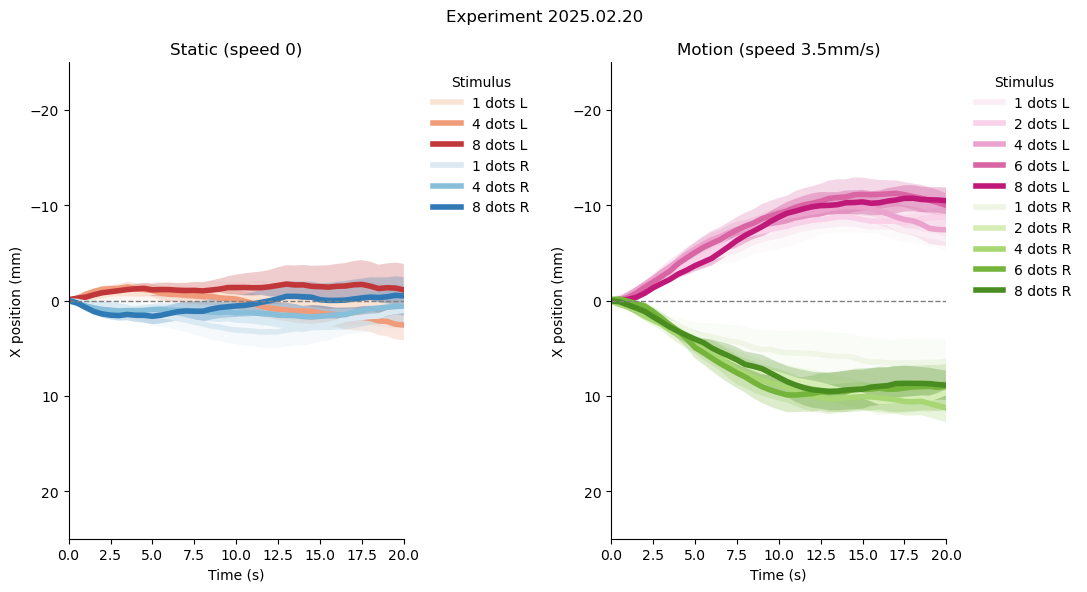

In [213]:
# Create subplots with 1 row and 2 columns (side by side)
fig, axes = plt.subplots(1, 2, figsize=(11, 6))

# Average x position per fish over time
s0_tmp_avg = s0_tmp.groupby(['fish_number', 'time', 'stim'])['x_mm'].mean().reset_index()
s3_tmp_avg = s3_tmp.groupby(['fish_number', 'time', 'stim'])['x_mm'].mean().reset_index()

# Data and titles to loop over
data_stimuli = [(s0_tmp_avg, ordered_color_map_s0, s0_c, 'Static (speed 0)'),
                (s3_tmp_avg, ordered_color_map_s3, s3_c, 'Motion (speed 3.5mm/s)')]

# Loop over each subplot
for ax, (data, color_map, stimulus_list, title) in zip(axes, data_stimuli):
    # Group and compute mean and SEM
    grouped = data.groupby(['stim', 'time'])['x_mm']
    mean_df = grouped.mean().reset_index()
    sem_df = grouped.sem().reset_index()

    # Merge mean and SEM
    merged = mean_df.merge(sem_df, on=['stim', 'time'], suffixes=('_mean', '_sem'))

    # Plot each stimulus
    for stim in stimulus_list:
        stim_data = merged[merged['stim'] == stim]
        if stim_data.empty:
            continue

        x = stim_data['time']
        y = stim_data['x_mm_mean']
        yerr = stim_data['x_mm_sem']
        color = color_map[stim]

        # Plot the mean line
        ax.plot(x, y, label=stim_label_map.get(stim, stim), color=color, linewidth=4)

        # Plot the shaded error area (SEM)
        ax.fill_between(x, y - yerr, y + yerr, color=color, alpha=0.25, edgecolor='none')

    # Styling
    ax.set_title(title)
    ax.set_ylim(25, -25)
    ax.set_xlim(0, 20)
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('X position (mm)')
    ax.axhline(0, color='grey', linestyle='--', lw=1)
    # ax.set_xticks(ax.get_xticks()[::2])
    # plt.setp(ax.get_xticklabels(), rotation=45, ha='right', fontsize=9)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Legend
    handles, labels = ax.get_legend_handles_labels()
    ordered_handles = [handles[labels.index(s)] for s in stimulus_list if s in labels]
    ordered_labels = [f'{s[1]} dots {s[-1]}' for s in stimulus_list if s in labels]
    ax.legend(ordered_handles, ordered_labels, title="Stimulus", bbox_to_anchor=(1.05, 1), loc='upper left', frameon=False)

# Suptitle and layout
fig.suptitle(f"Experiment {date.name}")
plt.tight_layout()
plt.savefig(path_figures / rf"xpos_allcond.pdf", dpi=1200, bbox_inches='tight')
plt.savefig(path_figures / rf"xpos_allcond.png", dpi=1200, bbox_inches='tight')
plt.show()


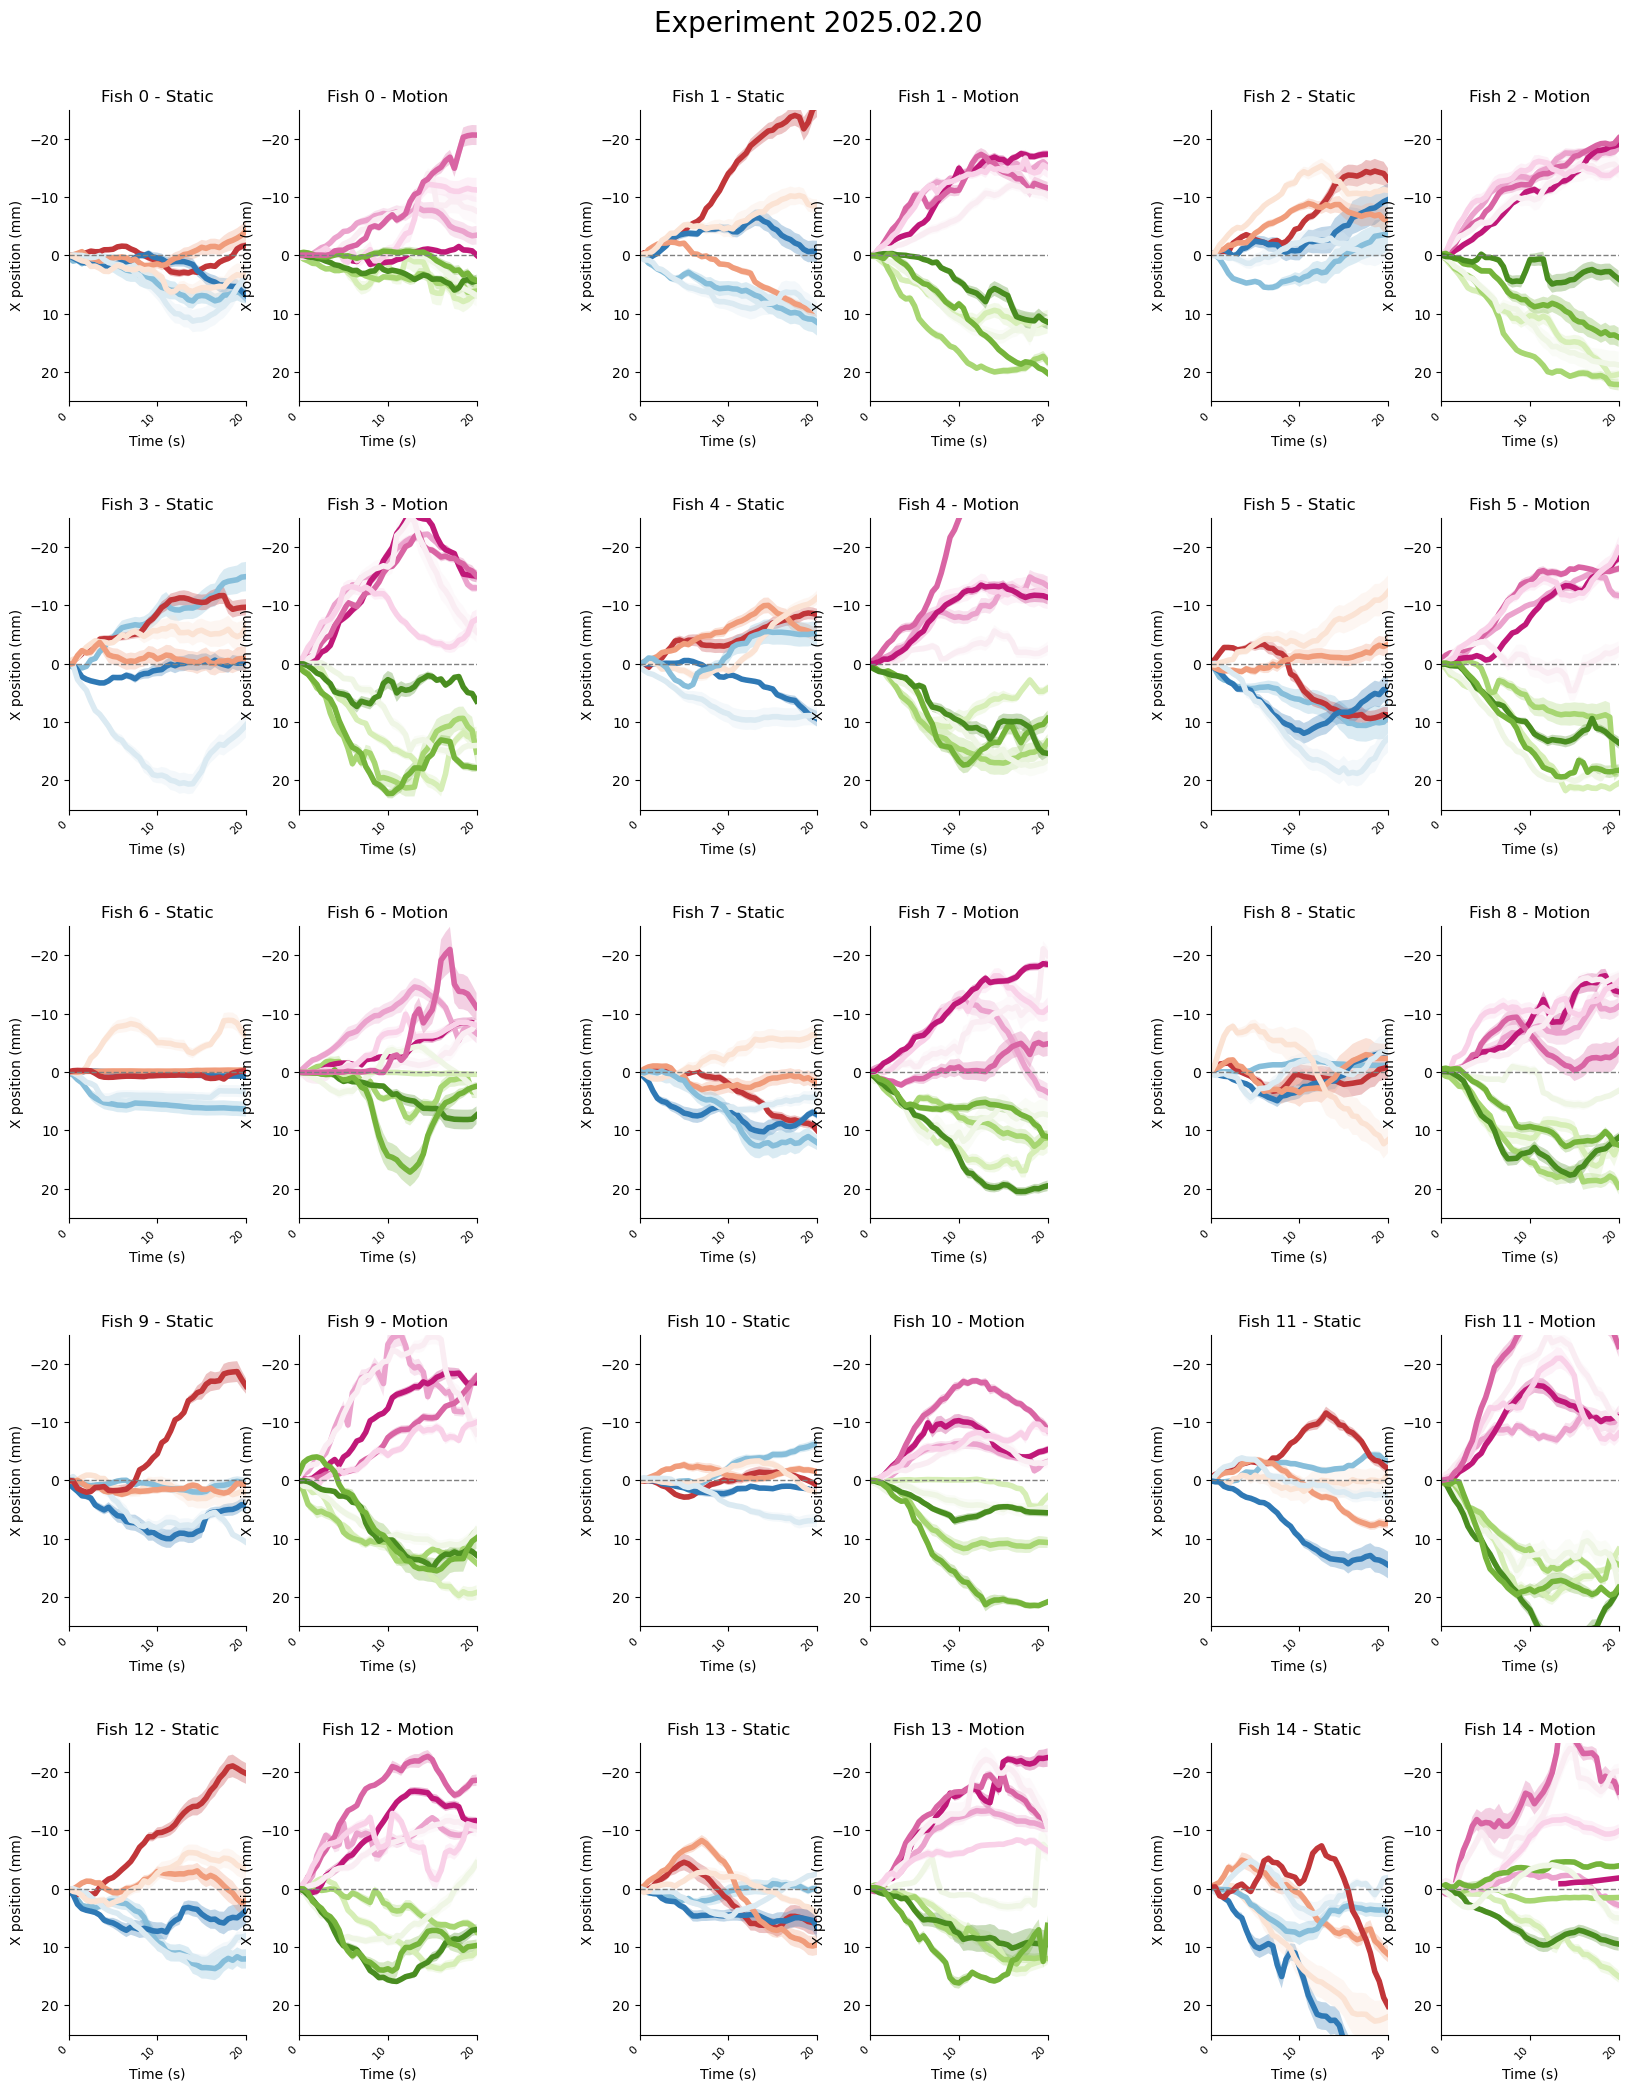

In [217]:
# Create a big figure with 5 rows and 3 columns (15 plots)
fig = plt.figure(figsize=(20, 25))
outer = gridspec.GridSpec(5, 3, wspace=0.4, hspace=0.4)

for f in range(n_fish):  # assume you have a list of 15 fish IDs
    inner = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=outer[f], wspace=0.3)

    # Filter data for this fish
    s0_fish = s0_tmp[(s0_tmp['fish_number'] == f) & (s0_tmp['dots_out'] < 1)]
    s3_fish = s3_tmp[(s3_tmp['fish_number'] == f) & (s3_tmp['dots_out'] < 1)]

    for idx, (data, color_map, title, ax_pos) in enumerate([
        (s0_fish, ordered_color_map_s0, f"Fish {f} - Static", inner[0]),
        (s3_fish, ordered_color_map_s3, f"Fish {f} - Motion", inner[1])
    ]):
        ax = plt.Subplot(fig, ax_pos)

        # Compute mean and SEM
        grouped = data.groupby(['stim', 'time'])['x_mm']
        mean_df = grouped.mean().reset_index()
        sem_df = grouped.sem().reset_index()
        merged = mean_df.merge(sem_df, on=['stim', 'time'], suffixes=('_mean', '_sem'))

        # Plot each stimulus
        for stim in data['stim'].unique():
            stim_data = merged[merged['stim'] == stim]
            if stim_data.empty:
                continue

            x = stim_data['time']
            y = stim_data['x_mm_mean']
            yerr = stim_data['x_mm_sem']
            color = color_map.get(stim, 'black')

            ax.plot(x, y, color=color, label=stim, linewidth=4)
            ax.fill_between(x, y - yerr, y + yerr, color=color, alpha=0.3, edgecolor='none')

        # Plot formatting
        ax.set_title(title)
        ax.set_ylim(25, -25)
        ax.set_xlim(0,20)
        ax.set_xlabel('Time (s)')
        ax.set_ylabel('X position (mm)')
        ax.axhline(0, color='grey', linestyle='--', lw=1)
        ax.set_xticks(ax.get_xticks()[::2])
        plt.setp(ax.get_xticklabels(), rotation=45, ha='right', fontsize=8)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

        fig.add_subplot(ax)

fig.suptitle(f"Experiment {date.name}", fontsize=20, y=0.92)

# Save if needed
plt.savefig(path_figures / rf"grid_eachfish_xpos_allcond.pdf", dpi=1200, bbox_inches='tight')
plt.savefig(path_figures / rf"grid_eachfish_xpos_allcond.png", dpi=1200, bbox_inches='tight')

plt.show()

#### Dots out

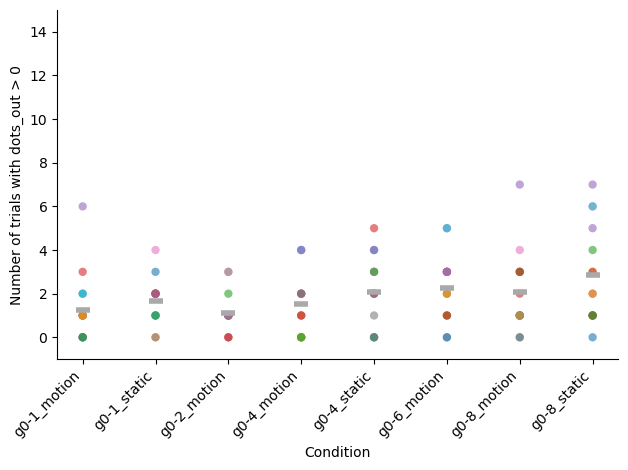

In [21]:
# 1. Filter to frame_count_stimulus == 0
df0 = fish_df_long[(fish_df_long['frame_count_stimulus'] == 0) & (fish_df_long['condition_grouped'] != 'inter_stim_pause')].copy()

# 2. For each trial, flag if either side has dots_out > 0
trial_flags = (df0.groupby(['fish_number', 'condition_grouped', 'trial_id'])['dots_out'].max().gt(0).reset_index(name='has_dots_out'))

# 3. Count trials with dots_out per fish and condition
summary = (trial_flags.groupby(['fish_number', 'condition_grouped']).agg(total_trials = ('trial_id', 'nunique'),
                                                                         trials_dots_out=('has_dots_out', 'sum')).reset_index())

summary['prop_with_dots'] = (summary['trials_dots_out'] / summary['total_trials'])

# 4. Compute average per condition
avg = summary.groupby('condition_grouped')['trials_dots_out'].mean().reset_index()

# 5. Plot
conditions = sorted(summary['condition_grouped'].unique())
x_pos = {cond: idx for idx, cond in enumerate(conditions)}

fig, ax = plt.subplots()

# Plot each fish
for fish in summary['fish_number'].unique():
    df_f = summary[summary['fish_number'] == fish]
    xs = [x_pos[c] for c in df_f['condition_grouped']]
    ys = df_f['trials_dots_out']
    ax.scatter(xs, ys, alpha=.6, edgecolors='none')

# Plot average
xs_avg = [x_pos[c] for c in avg['condition_grouped']]
ys_avg = avg['trials_dots_out']
ax.scatter(xs_avg, ys_avg, marker='_', s=100,linewidths=4, color='darkgray')

ax.set_xticks(list(x_pos.values()))
ax.set_xticklabels(list(x_pos.keys()), rotation=45, ha='right')
ax.set_xlabel('Condition')
ax.set_ylabel('Number of trials with dots_out > 0')
ax.set_ylim(-1, 15)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

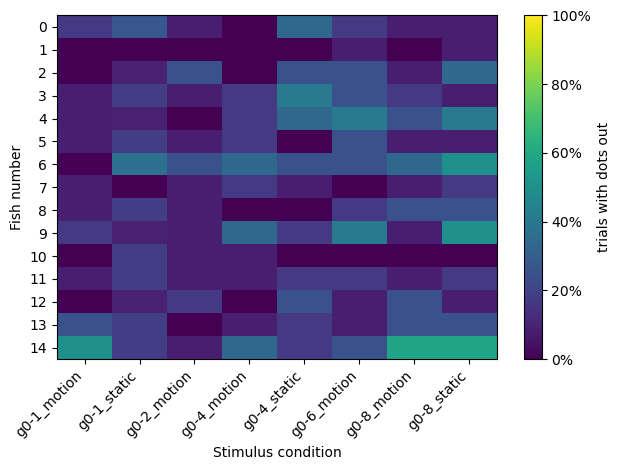

In [31]:
plt.show()
from matplotlib.ticker import PercentFormatter

pivot = summary.pivot(index='fish_number', columns='condition_grouped', values='prop_with_dots')

fig, ax = plt.subplots()
im = ax.imshow(pivot, aspect='auto', vmin=0, vmax=1)

ax.set_xticks(np.arange(pivot.shape[1]))
ax.set_xticklabels(pivot.columns, rotation=45, ha='right')

ax.set_yticks(np.arange(pivot.shape[0]))
ax.set_yticklabels(pivot.index)

plt.colorbar(im, ax=ax, label='trials with dots out', format=PercentFormatter(1.0))
ax.set_xlabel('Stimulus condition')
ax.set_ylabel('Fish number')
plt.tight_layout()
plt.show()